In [1]:
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt

from lib import neurons, input_gen, driver, utils

In [2]:
hyper = neurons.HyperConfig1(nd=200, ns=300, n=10, b=2., bk=5.5, beta=13.5153)
hyperD = neurons.HyperDynConfig1(b=2., bk=5.5, beta=13.5153)
neuron = neurons.Neuron_Decay_Int(hyper)
xs_gen = input_gen.Normal(nd=hyper.nd, ns=hyper.ns)

my_driver = driver.Driver1_bScan_activationScan(
    neuron=neuron,
    xs_generator=xs_gen,
    rng=jax.random.PRNGKey(333),
    hyperD=hyperD,
    initial_state=None,
    resample_every=1000,
    n_tested_patterns=1000,
)

In [11]:
my_driver.run(
    n_init_steps=8000,
    n_steps_phase1=3000,
    n_steps_phase2=20000,
    n_steps_phase3=10000,
    test_every_phase3=50,
    bs=jnp.array([1.35, 1.5, 1.7, 1.85, 2., 2.15, 2.3, 2.45, 2.6, 2.75, 2.9, 3., 3.15, 3.3]),
    window_lens=jnp.array([0.1, 0.5, 1.0, 1.5, 2.0]),
)

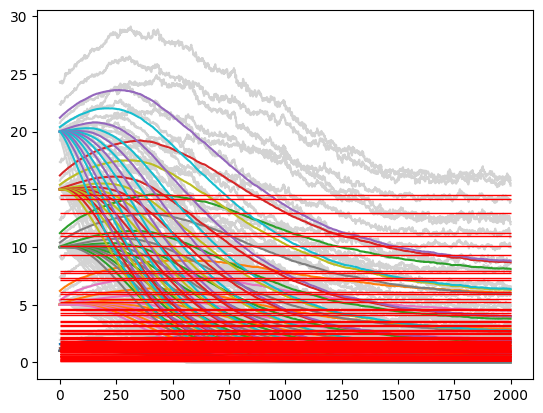

In [7]:
mean = np.mean(my_driver.transient_record, axis=-1)
lower = np.percentile(my_driver.transient_record, 1, axis=-1)
upper = np.percentile(my_driver.transient_record, 99, axis=-1)

steady_upper = np.percentile(my_driver.steady_record, 99, axis=-1)
steady_upper = np.mean(steady_upper, axis=0)

plt.plot(upper, color='lightgrey')
plt.plot(lower, color='lightgrey')
plt.plot(mean)
plt.hlines(steady_upper, 0, 2000, colors='red', linestyles='-', linewidth=1)

In [8]:
utils.capacity_numba(my_driver.transient_record, my_driver.steady_record)

array([  0.        ,   0.        ,   0.        , 468.        ,
       530.5       ,   0.        ,   0.        , 289.        ,
       528.        , 583.66666667,   0.        ,   0.        ,
       526.625     , 593.5       , 603.        ,   0.        ,
       472.        , 585.75      , 607.        , 620.        ,
       298.4       , 528.66666667, 602.        , 607.        ,
       617.        , 464.5       , 558.25      , 601.        ,
       610.        , 616.5       , 510.5       , 574.        ,
       601.        , 607.        , 605.        , 525.33333333,
       563.        , 600.        , 602.        , 596.5       ,
       548.        , 578.        , 589.33333333, 584.        ,
       580.        , 557.        , 573.        , 572.5       ,
       563.5       , 563.5       , 517.        , 544.        ,
       546.        , 536.        , 536.        , 488.        ,
       536.        , 526.33333333, 526.33333333, 526.33333333,
       514.75      , 500.        , 489.        , 489.  

In [10]:
my_driver.hyperD = neurons.HyperDynConfig1(b=2., bk=6.5, beta=13.5153)